# UnequalTime: demo

This notebook measures the unequal-time angular power spectra $\mathcal Z_\ell(\omega)$ of a small test catalog, compares them
with linear theory and its covariance, and fits the clustering amplitude. It needs the package installed (`pip install -e ..`
from this directory) and matplotlib, and runs in a few minutes.

The catalog (`data/catalog.npz`, made by `make_catalog.py`) contains galaxies Poisson-sampled from a Gaussian linear
density field with bias $b(z) = 0.7 + 0.5z$ and Kaiser redshift-space distortions on wavenumbers $k < 0.05\,h/{\rm Mpc}$, over
$0.1 < z < 0.7$, in a footprint with varying completeness (`data/mask.fits`).

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import unequaltime as ut

cat = np.load('data/catalog.npz')
ra, dec, z = cat['ra'], cat['dec'], cat['z']
mask = hp.read_map('data/mask.fits')          # angular selection Omega(n), HEALPix (RING)
cosmo = dict(np.load('data/cosmology.npz'))   # z, chi, D, f, k, pk (Mpc/h units)
nside = hp.npix2nside(len(mask))
print(f'{len(z)} galaxies, nside {nside}')

353882 galaxies, nside 64


## Inputs

We use two redshift bins and 16 radial frequencies per bin, in multiples of $\pi/\Delta z$ for bin width $\Delta z$. The theory
and covariance also need the background density $\bar n(z)$ per unit redshift and steradian, with
$\bar n_g(\hat{\mathbf{n}},z) = \bar n(z)\Omega(\hat{\mathbf{n}})$, which we estimate from the catalog. (The estimator itself does not need
it: by default it estimates $\bar n(z)$ from the catalog and accounts for the resulting radial integral constraint.)

[Text(0.5, 0, '$z$'),
 Text(0, 0.5, '$\\bar n(z)$ [per unit $z$, per sr]'),
 Text(0.5, 1.0, 'background density and redshift bins')]

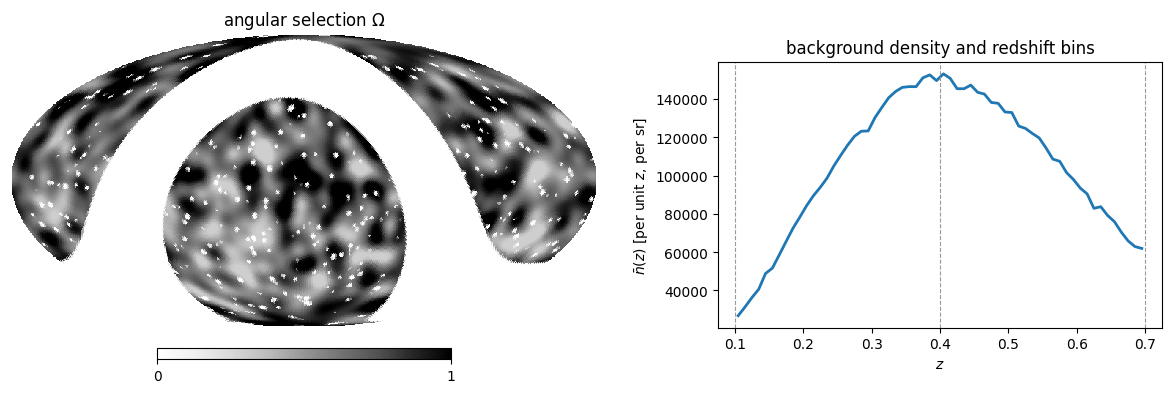

In [2]:
zbins = np.array([0.1, 0.4, 0.7])
nomega = 16
omega = np.pi * np.arange(nomega) / np.diff(zbins)[:, None]       # (bin, m)

counts, z_edges = np.histogram(z, 60, (zbins[0], zbins[-1]))
area = mask.sum() * hp.nside2pixarea(nside)                       # int dn Omega(n)
z_mid = (z_edges[1:] + z_edges[:-1]) / 2
nz = lambda x: np.interp(x, z_mid, counts / np.diff(z_edges) / area)

fig = plt.figure(figsize=(12, 3.8))
hp.mollview(mask, title=r'angular selection $\Omega$', sub=(1, 2, 1), cmap='Greys', min=0, max=1)
ax = fig.add_axes([0.6, 0.15, 0.37, 0.7])
ax.plot(z_mid, nz(z_mid), lw=2)
for edge in zbins:
    ax.axvline(edge, color='0.6', lw=0.8, ls='--')
ax.set(xlabel='$z$', ylabel=r'$\bar n(z)$ [per unit $z$, per sr]', title='background density and redshift bins')

## Measurement

`window` computes the mask operators once (mode coupling, pixel window, shot-noise shape); `measure` returns
$\widehat{\mathcal Z}_\ell(\omega)$ in multipole bands, with shape (redshift bin, frequency, multipole band).

In [3]:
ell_edges = np.arange(2, 123, 8)
ell = (ell_edges[1:] + ell_edges[:-1] - 1) / 2

win = ut.window(mask, ell_edges)
Z = ut.measure(ra, dec, z, win, zbins, nomega)
print(Z.shape)

(2, 16, 15)


## Theory and covariance

`spectra` computes the full-sky linear theory of all frequency pairs (here up to the catalog's $k_{\max}$); `mean` applies the
mask, and `covariance` gives the Gaussian covariance of the measurement, including shot noise and the correlations between
frequencies and redshift bins.

In [4]:
b = lambda x: 0.7 + 0.5 * x
G, Gt = ut.spectra(cosmo, b, nz, zbins, nomega, lmax=3 * nside - 1, kmax=0.05)
Z_th = ut.mean(G, Gt, win)
cov = ut.covariance(G, Gt, nz, zbins, win)
err = np.sqrt(cov.diagonal()).reshape(Z.shape)

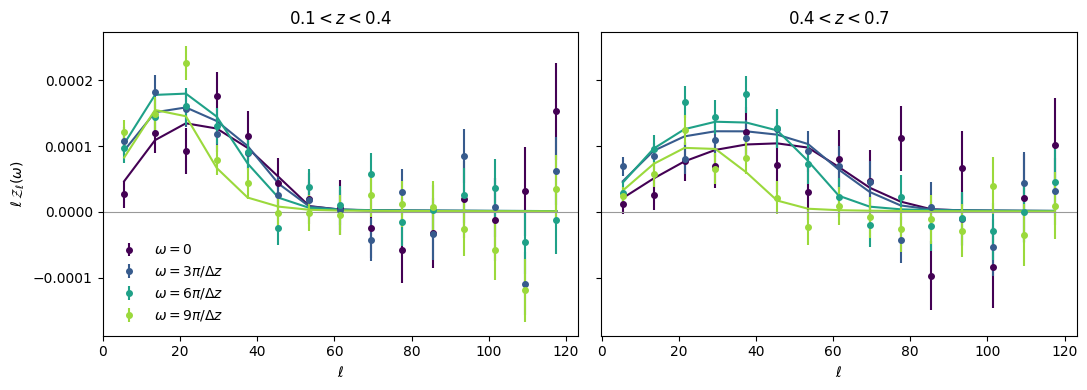

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.85, 4))
for ibin, ax in enumerate(axes):
    for color, m in zip(colors, (0, 3, 6, 9)):
        ax.errorbar(ell, ell * Z[ibin, m], ell * err[ibin, m], fmt='o', ms=4, color=color, label=rf'$\omega = {m}\pi/\Delta z$' if m else r'$\omega = 0$')
        ax.plot(ell, ell * Z_th[ibin, m], color=color, lw=1.5)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set(xlabel=r'$\ell$', title=f'${zbins[ibin]} < z < {zbins[ibin + 1]}$')
axes[0].set_ylabel(r'$\ell\,\mathcal{Z}_\ell(\omega)$')
axes[0].legend(frameon=False)
plt.tight_layout()

Points show the measurement and lines the theory. $\mathcal Z_\ell(0)$ is proportional to the angular power spectrum of the bin;
higher frequencies select shorter radial wavelengths. The same spectra as a function of $\omega$, for a few multipole bands:

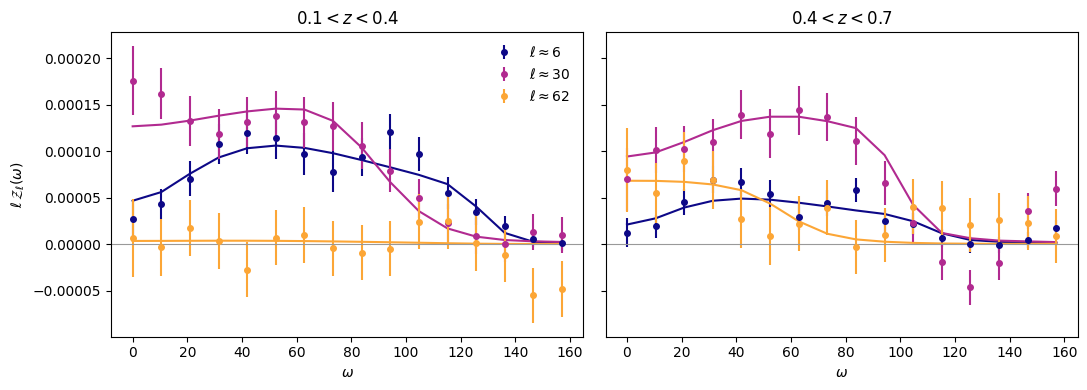

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = plt.cm.plasma(np.linspace(0, 0.8, 3))
for ibin, ax in enumerate(axes):
    for color, i in zip(colors, (0, 3, 7)):
        ax.errorbar(omega[ibin], ell[i] * Z[ibin, :, i], ell[i] * err[ibin, :, i], fmt='o', ms=4, color=color,
                    label=rf'$\ell \approx {ell[i]:.0f}$')
        ax.plot(omega[ibin], ell[i] * Z_th[ibin, :, i], color=color, lw=1.5)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set(xlabel=r'$\omega$', title=f'${zbins[ibin]} < z < {zbins[ibin + 1]}$')
axes[0].set_ylabel(r'$\ell\,\mathcal{Z}_\ell(\omega)$')
axes[0].legend(frameon=False)
plt.tight_layout()

## Fitting the clustering amplitude

With the covariance we can fit an amplitude $A$ to the model, $\mathcal Z = A\,\mathcal Z^{\rm th}$; the catalog has $A = 1$.
`width` averages $\mathcal Z_\ell(\omega)$ over bands of frequencies (the same option is passed to `mean` and `covariance`).

In [7]:
def fit(Z, Z_th, cov):
    d, t, icov = Z.ravel(), Z_th.ravel(), np.linalg.inv(cov)
    A, sigma = (t @ icov @ d) / (t @ icov @ t), (t @ icov @ t)**-0.5
    chi2 = (d - A * t) @ icov @ (d - A * t)
    print(f'A = {A:.3f} +- {sigma:.3f};  chi2 = {chi2:.1f} for {len(d) - 1} degrees of freedom')

fit(Z, Z_th, cov)
fit(ut.measure(ra, dec, z, win, zbins, nomega, width=3), ut.mean(G, Gt, win, width=3), ut.covariance(G, Gt, nz, zbins, win, width=3))

A = 1.017 +- 0.034;  chi2 = 472.6 for 479 degrees of freedom


A = 1.016 +- 0.035;  chi2 = 170.5 for 179 degrees of freedom


## All frequency pairs

With `pairs=True`, `measure` returns the cross-spectra $\mathcal Z_\ell(\omega_A, \pm\omega_B)$ of all pairs of frequency bands,
which describe the radial correlations beyond $\mathcal Z_\ell(\omega)$. The rows of the data vector are labelled by `ut.rows`
as (kind, A, B, real/imaginary part). Here is the real part of $\mathcal Z_\ell(\omega_i, \omega_j)$ for all frequencies
(`width=1`) in the multipole band $\ell \approx 22$:

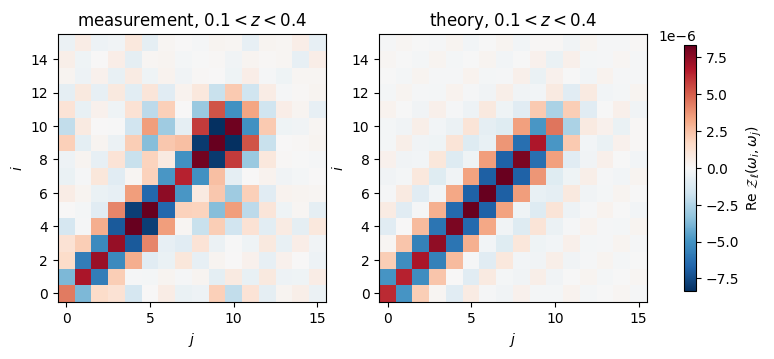

In [8]:
X = ut.measure(ra, dec, z, win, zbins, nomega, pairs=True)
X_th = ut.mean(G, Gt, win, pairs=True)
labels = ut.rows(nomega)

def matrix(x, ibin, iell):                                        # Re Z(omega_i, +omega_j) as a symmetric matrix
    out = np.zeros((nomega, nomega))
    for (kind, A, B, part), value in zip(labels, x[ibin, :, iell]):
        if kind == 0 and part == 0:
            out[A, B] = out[B, A] = value
    return out

iell = 2
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
vmax = np.abs(matrix(X_th, 0, iell)).max()
for ax, x, title in zip(axes, (X, X_th), ('measurement', 'theory')):
    im = ax.imshow(matrix(x, 0, iell), cmap='RdBu_r', vmin=-vmax, vmax=vmax, origin='lower')
    ax.set(xlabel='$j$', ylabel='$i$', title=f'{title}, ${zbins[0]} < z < {zbins[1]}$')
fig.colorbar(im, ax=axes, shrink=0.8, label=r'Re $\mathcal{Z}_\ell(\omega_i, \omega_j)$')

The covariance of the pairs grows quickly with the number of frequency bands, so for fits it is convenient to use bands of a few
frequencies:

In [9]:
opts = dict(width=3, pairs=True)
fit(ut.measure(ra, dec, z, win, zbins, nomega, **opts), ut.mean(G, Gt, win, **opts), ut.covariance(G, Gt, nz, zbins, win, **opts))

A = 1.065 +- 0.041;  chi2 = 1961.7 for 1979 degrees of freedom
